# Querying a 10 GB cell atlas without loading it

You found an atlas you want on [CELLxGENE](https://cellxgene.cziscience.com/):
the **ocular surface atlas** — 815,769 cells from human cornea, sclera, and
limbus, published as a single 10 GB `.h5ad` file.

But you only care about one thing: the **endothelial cells** in the cornea — a
rare population, a few thousand out of 815,769. The usual workflow forces you to
load all 10 GB into memory just to read less than 1% of it.

This notebook does the opposite. We open a **31 MB stand-in** for that 10 GB file
and work with it as an ordinary `AnnData` — but slicing it reads only the cells we
ask for. The full matrix is never loaded.

## The stand-in: a virtual repository

A publisher ran one command over the atlas file:

```python
from tutorial.rectilinear_concat import virtualize_matrix
virtualize_matrix(".../30127f02-...-e5b77e4989bd.h5ad", "repo/ocular10")
```

That produced `repo/ocular10` — an [Icechunk](https://icechunk.io) repository that
**references** the original file's byte ranges instead of copying them, and bakes
in the cell- and gene-level metadata. It is 31 MB and stands in for the 10 GB
original. As a reader, you never run that command; you just open the repo.

> The same command works against a remote `https://` URL, in which case reads
> stream from the cloud. Here the repo points at a local copy of the file, so the
> walkthrough runs fast and doesn't hit the public server on every execution.

In [1]:
from tutorial.rectilinear_concat import open_anndata

import subprocess
print(subprocess.run(["du", "-sh", "repo/ocular10"], capture_output=True, text=True).stdout.strip(),
      "  (stands in for a 10 GB file)")

31M	repo/ocular10   (stands in for a 10 GB file)


## Open it — instantly

`open_anndata` returns an ordinary `AnnData`. Nothing is loaded: the expression
matrix `X` is *backed* (read on demand), and `obs`/`var` were stored in the repo
when it was built. From here on, you use it like any other `AnnData`.

In [2]:
import time
t = time.time()
adata = open_anndata("repo/ocular10")
print(f"opened in {time.time() - t:.2f}s")
adata

opened in 0.43s


AnnData object with n_obs × n_vars = 815769 × 35477
    obs: 'reference_genome', 'gene_annotation_version', 'alignment_software', 'intronic_reads_counted', 'donor_id', 'donor_age', 'self_reported_ethnicity_ontology_term_id', 'donor_living_at_sample_collection', 'sample_id', 'sample_preservation_method', 'tissue_ontology_term_id', 'development_stage_ontology_term_id', 'sample_collection_method', 'tissue_source', 'tissue_type', 'suspension_derivation_process', 'suspension_dissociation_reagent', 'suspension_dissociation_time', 'suspension_uuid', 'suspension_type', 'library_id', 'assay_ontology_term_id', 'sequenced_fragment', 'institute', 'library_id_repository', 'is_primary_data', 'cell_type_ontology_term_id', 'author_cell_type', 'disease_ontology_term_id', 'sex_ontology_term_id', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'pANN', 'study', 'sampleid', 'published_annotation', 'majorclass', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'o

## Metadata exploration is free

Every per-cell field (`adata.obs`) and per-gene field (`adata.var`) lives inside
the 31 MB repo, so slicing, grouping, and counting them touches **none** of the
10 GB matrix. You can get to know the whole atlas before reading any expression
data at all.

In [3]:
adata.obs["tissue"].value_counts()

tissue
corneo-scleral junction         344463
cornea                          249397
sclera                           99976
ocular surface region            95132
tunica fibrosa of eyeball        14853
substantia propria of cornea      6909
corneal epithelium                4199
corneal endothelium                840
Name: count, dtype: int64

In [4]:
# Which cell types appear in which tissue? (815,769 cells summarized; no matrix read)
import pandas as pd
pd.crosstab(adata.obs["cell_type"], adata.obs["tissue"]).loc[
    :, ["cornea", "sclera", "corneo-scleral junction"]
]

tissue,cornea,sclera,corneo-scleral junction
cell_type,,,
fibroblast,20681,53755,83695
epithelial cell,116309,1558,98945
blood vessel endothelial cell,299,1538,2030
mast cell,53,69,521
endothelial cell,3462,11062,16146
corneal endothelial cell,231,0,7
melanocyte,1128,1230,4992
smooth muscle cell,166,2717,334
myelinating Schwann cell,91,197,371


## The question: a rare cell population

Endothelial cells are a small minority of this ocular atlas — in the cornea samples
they are well under 1% of cells (the authors label them `CC_VenEndo`, vascular
endothelium). A rare population is exactly where loading the whole matrix hurts
most, and where metadata-only filtering shines: we can pick them out with a boolean
mask over `obs`, before reading any expression data.

In [5]:
mask = (adata.obs["tissue"] == "cornea") & (adata.obs["cell_type"] == "endothelial cell")
print(f"endothelial cells in cornea: {mask.sum():,} of {adata.n_obs:,} "
      f"({100 * mask.mean():.2f}%)")
print("...selected from metadata alone, without reading a single expression value.")

endothelial cells in cornea: 3,462 of 815,769 (0.42%)
...selected from metadata alone, without reading a single expression value.


## Read just those cells

Subset the `AnnData` the way you always would — `adata[mask]` — and call
`.to_memory()` to pull the expression values. Because `X` is backed by the repo,
this reads only the byte ranges for those rows; the other 99.6% of the matrix is
never touched. No special API: it's the ordinary AnnData idiom.

In [6]:
t = time.time()
endo = adata[mask].to_memory()
print(f"read {endo.n_obs:,} cells x {endo.n_vars:,} genes in {time.time() - t:.1f}s")
print(f"non-zero entries read: {endo.X.nnz:,}")
print(f"data touched: ~{endo.X.nnz * 8 / 1e6:.0f} MB  (vs. 10,000 MB for the whole file)")

read 3,462 cells x 35,477 genes in 1.3s
non-zero entries read: 5,493,207
data touched: ~44 MB  (vs. 10,000 MB for the whole file)


## Do some science — the usual scanpy way

A quick check that we really pulled endothelial cells: compare them against a
matched random sample of corneal **epithelial** cells. We read both subsets, then
hand them to ordinary [scanpy](https://scanpy.readthedocs.io/) — normalize, log,
and a marker dot plot. Nothing here knows the data is virtual.

- **PECAM1, CDH5, VWF** — endothelial markers
- **KRT12, KRT3, KRT14** — corneal epithelial keratins

In [7]:
import numpy as np
import anndata as ad
import scanpy as sc

rng = np.random.default_rng(0)
epi_idx = np.flatnonzero(
    ((adata.obs["tissue"] == "cornea") & (adata.obs["cell_type"] == "epithelial cell")).to_numpy()
)
epi = adata[np.sort(rng.choice(epi_idx, size=endo.n_obs, replace=False))].to_memory()

sub = ad.concat([endo, epi], merge="same")   # the ~6,900 cells we care about, in memory
sub.obs["cell_type"] = sub.obs["cell_type"].cat.remove_unused_categories()
sub.obs["cell_type"].value_counts()

cell_type
endothelial cell    3462
epithelial cell     3462
Name: count, dtype: int64

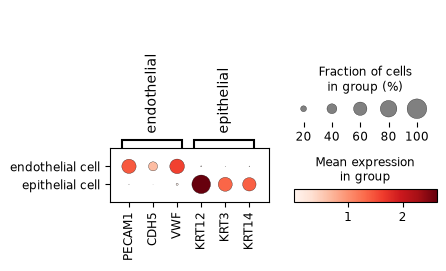

In [8]:
sc.pp.normalize_total(sub, target_sum=1e4)   # standard scanpy preprocessing
sc.pp.log1p(sub)

markers = {"endothelial": ["PECAM1", "CDH5", "VWF"], "epithelial": ["KRT12", "KRT3", "KRT14"]}
sc.pl.dotplot(sub, markers, groupby="cell_type", gene_symbols="feature_name")

The endothelial markers light up in the endothelial cells and the keratins in the
epithelial cells — exactly as they should. We confirmed a real signal having read
only the ~6,900 cells we cared about.

## What just happened

| | |
|---|---|
| Opened the atlas | instant — nothing loaded |
| Explored 815,769 cells of metadata | free — lives in the 31 MB repo |
| Read expression for the cells we selected | seconds — only their byte ranges |
| Loaded the 10 GB matrix | **never** |

The repository is a thin, self-contained index that points back at the original
file. You use it as a normal `AnnData`: metadata questions are answered locally and
instantly, and `adata[mask].to_memory()` reads only the cells you select. The same
code works for any selection — one donor, two cell types across several tissues, a
random sample — and only ever moves the data you actually use. Point the same repo
at the file's `https://` URL and these reads come from the cloud.